# Aging-brain MERFISH: slices colored by cell type

Spatial cell-type maps adapted from `brca_xenium_chromium/XeniumSliceMorphology.ipynb`. Includes every spatial slice in the configured directory. Uses `cell_type` labels and `center_x`/`center_y` coordinates. Brain MERFISH measured coordinates are converted from mm to µm; CosMx is displayed in native global pixels. Aging brain uses the regenerated milestone-87 input files.

Only observation metadata is read. Cells with invalid coordinates or missing/unassigned labels are excluded and reported; no count QC is applied. Colors are shared across all slices. Each slice has its own spatial extent, with equal x/y scale within that panel. `INVERT_Y_AXIS` controls image orientation. PNG, PDF and a coverage CSV are exported to a new filename on each run.


Cell-type colors are grouped into broader families using related shades, with family headings in the legend. Edit `CELL_TYPE_FAMILIES` to change the grouping. The exported `_colors.csv` records each label, family and color.


In [13]:
from pathlib import Path
import math
import h5py
import anndata as ad
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display

sns.set_theme(style="white", context="paper")
DATA_DIR = Path('/work/magroup/skrieger/Syndri/data/datasets/agingbrain_merfish/results/model_runs/10x_agingbrain_donors5to8_m87_regenerated_rctd_20261010')
SLICE_GLOB = '*.h5ad'
X_KEY, Y_KEY = 'center_x', 'center_y'
CELL_TYPE_KEY = 'cell_type'
COORDINATE_SCALE = 1.0
COORDINATE_UNITS = 'µm'
INVERT_Y_AXIS = True  # Display in image orientation; toggle to reverse the vertical axis.
N_COLS = 3
POINT_SIZE = 4.5
FIG_DPI = 180
OUTPUT_DIR = Path('/home/jwinchel/Syndri/figures/outputs/slice_morphology')
OUTPUT_PREFIX = 'agingbrain_merfish_cell_types'


In [14]:
slice_paths = sorted(DATA_DIR.glob(SLICE_GLOB))
if not slice_paths:
    raise FileNotFoundError(f'No files matching {SLICE_GLOB!r} in {DATA_DIR}')
slices, coverage = [], []
for path in slice_paths:
    # Read .obs only, avoiding all expression and correction matrices.
    with h5py.File(path,'r') as handle:
        obs = ad.io.read_elem(handle['obs'])
    required = [X_KEY, Y_KEY, CELL_TYPE_KEY]
    absent = [key for key in required if key not in obs]
    if absent:raise KeyError(f'{path.name}: missing columns {absent}')
    frame = obs[required].copy()
    frame.columns = ['x','y','cell_type']
    frame['x'] = pd.to_numeric(frame.x,errors='coerce') * COORDINATE_SCALE
    frame['y'] = pd.to_numeric(frame.y,errors='coerce') * COORDINATE_SCALE
    frame['cell_type'] = frame.cell_type.astype('string').str.strip()
    valid_xy = np.isfinite(frame[['x','y']].to_numpy(dtype=float)).all(axis=1)
    valid_label = frame.cell_type.notna() & ~frame.cell_type.str.lower().isin(['','nan','none','unassigned','<na>'])
    keep = valid_xy & valid_label.to_numpy()
    sample = path.stem.removeprefix('st_integrated_slice-').removeprefix('st_integrated_MsBrainAgingSpatialDonor_')
    coverage.append(dict(slice=sample,n_total=len(frame),n_plotted=int(keep.sum()),
                         n_invalid_coordinates=int((~valid_xy).sum()),
                         n_missing_or_unassigned_labels=int((~valid_label).sum())))
    slices.append((sample,frame.loc[keep].copy()))
coverage = pd.DataFrame(coverage)
display(coverage)
print(f'Loaded metadata for {len(slices)} slices')
# Related labels share a sequential color family, as in the Xenium notebook.
observed_types = {str(c) for _,frame in slices for c in frame.cell_type.unique()}
if not observed_types:raise ValueError('No cells with valid coordinates and labels')
CELL_TYPE_FAMILIES = [('Neurons', 'Blues', ['neuron', 'inhibitory interneuron', 'medium spiny neuron']), ('Glia', 'Greens', ['astrocyte', 'oligodendrocyte precursor cell', 'oligodendrocyte']), ('Immune', 'Reds', ['microglial cell', 'macrophage', 'T cell']), ('Vascular / perivascular', 'Purples', ['endothelial cell', 'pericyte', 'vascular leptomeningeal cell']), ('Unresolved', 'Greys', ['cell'])]

family_groups = []
for family,cmap,labels in CELL_TYPE_FAMILIES:
    if labels is None:
        suffix = ' Glut' if family == 'Glutamatergic neurons' else ' GABA'
        labels = sorted(c for c in observed_types if c.endswith(suffix))
    labels = [c for c in labels if c in observed_types]
    if labels:family_groups.append((family,cmap,labels))
assigned = [c for _,_,labels in family_groups for c in labels]
if len(assigned) != len(set(assigned)):raise ValueError('A cell type occurs in more than one family')
additional = sorted(observed_types.difference(assigned))
if additional:family_groups.append(('Other / unmapped','Greys',additional))
cell_type_order = [c for _,_,labels in family_groups for c in labels]
palette_dict,cell_type_family = {},{}
for family,cmap,labels in family_groups:
    # Avoid near-white shades so cells remain visible on the white background.
    shades = plt.get_cmap(cmap)(np.linspace(.4,.88,len(labels)))
    for label,color in zip(labels,shades):
        palette_dict[label] = color
        cell_type_family[label] = family
family_color_table = pd.DataFrame([
    dict(family=cell_type_family[c],cell_type=c,color=__import__('matplotlib').colors.to_hex(palette_dict[c]))
    for c in cell_type_order
])
display(family_color_table)


,slice,n_total,n_plotted,n_invalid_coordinates,n_missing_or_unassigned_labels
0,5_0,10744,10744,0,0
1,5_1,9644,9644,0,0
2,5_2,8983,8983,0,0
3,6_0,9462,9462,0,0
4,6_1,8164,8164,0,0
5,6_2,8281,8281,0,0
6,7_0,10785,10785,0,0
7,7_1,10609,10609,0,0
8,7_2,11398,11398,0,0
9,8_0,14122,14122,0,0


Loaded metadata for 12 slices


,family,cell_type,color
0,Neurons,neuron,#94c4df
1,Neurons,inhibitory interneuron,#3e8ec4
2,Neurons,medium spiny neuron,#084f99
3,Glia,astrocyte,#98d594
4,Glia,oligodendrocyte precursor cell,#3ea75a
5,Glia,oligodendrocyte,#006b2b
6,Immune,microglial cell,#fc8a6a
7,Immune,macrophage,#eb372a
8,Immune,T cell,#a10e15
9,Vascular / perivascular,endothelial cell,#b6b6d8


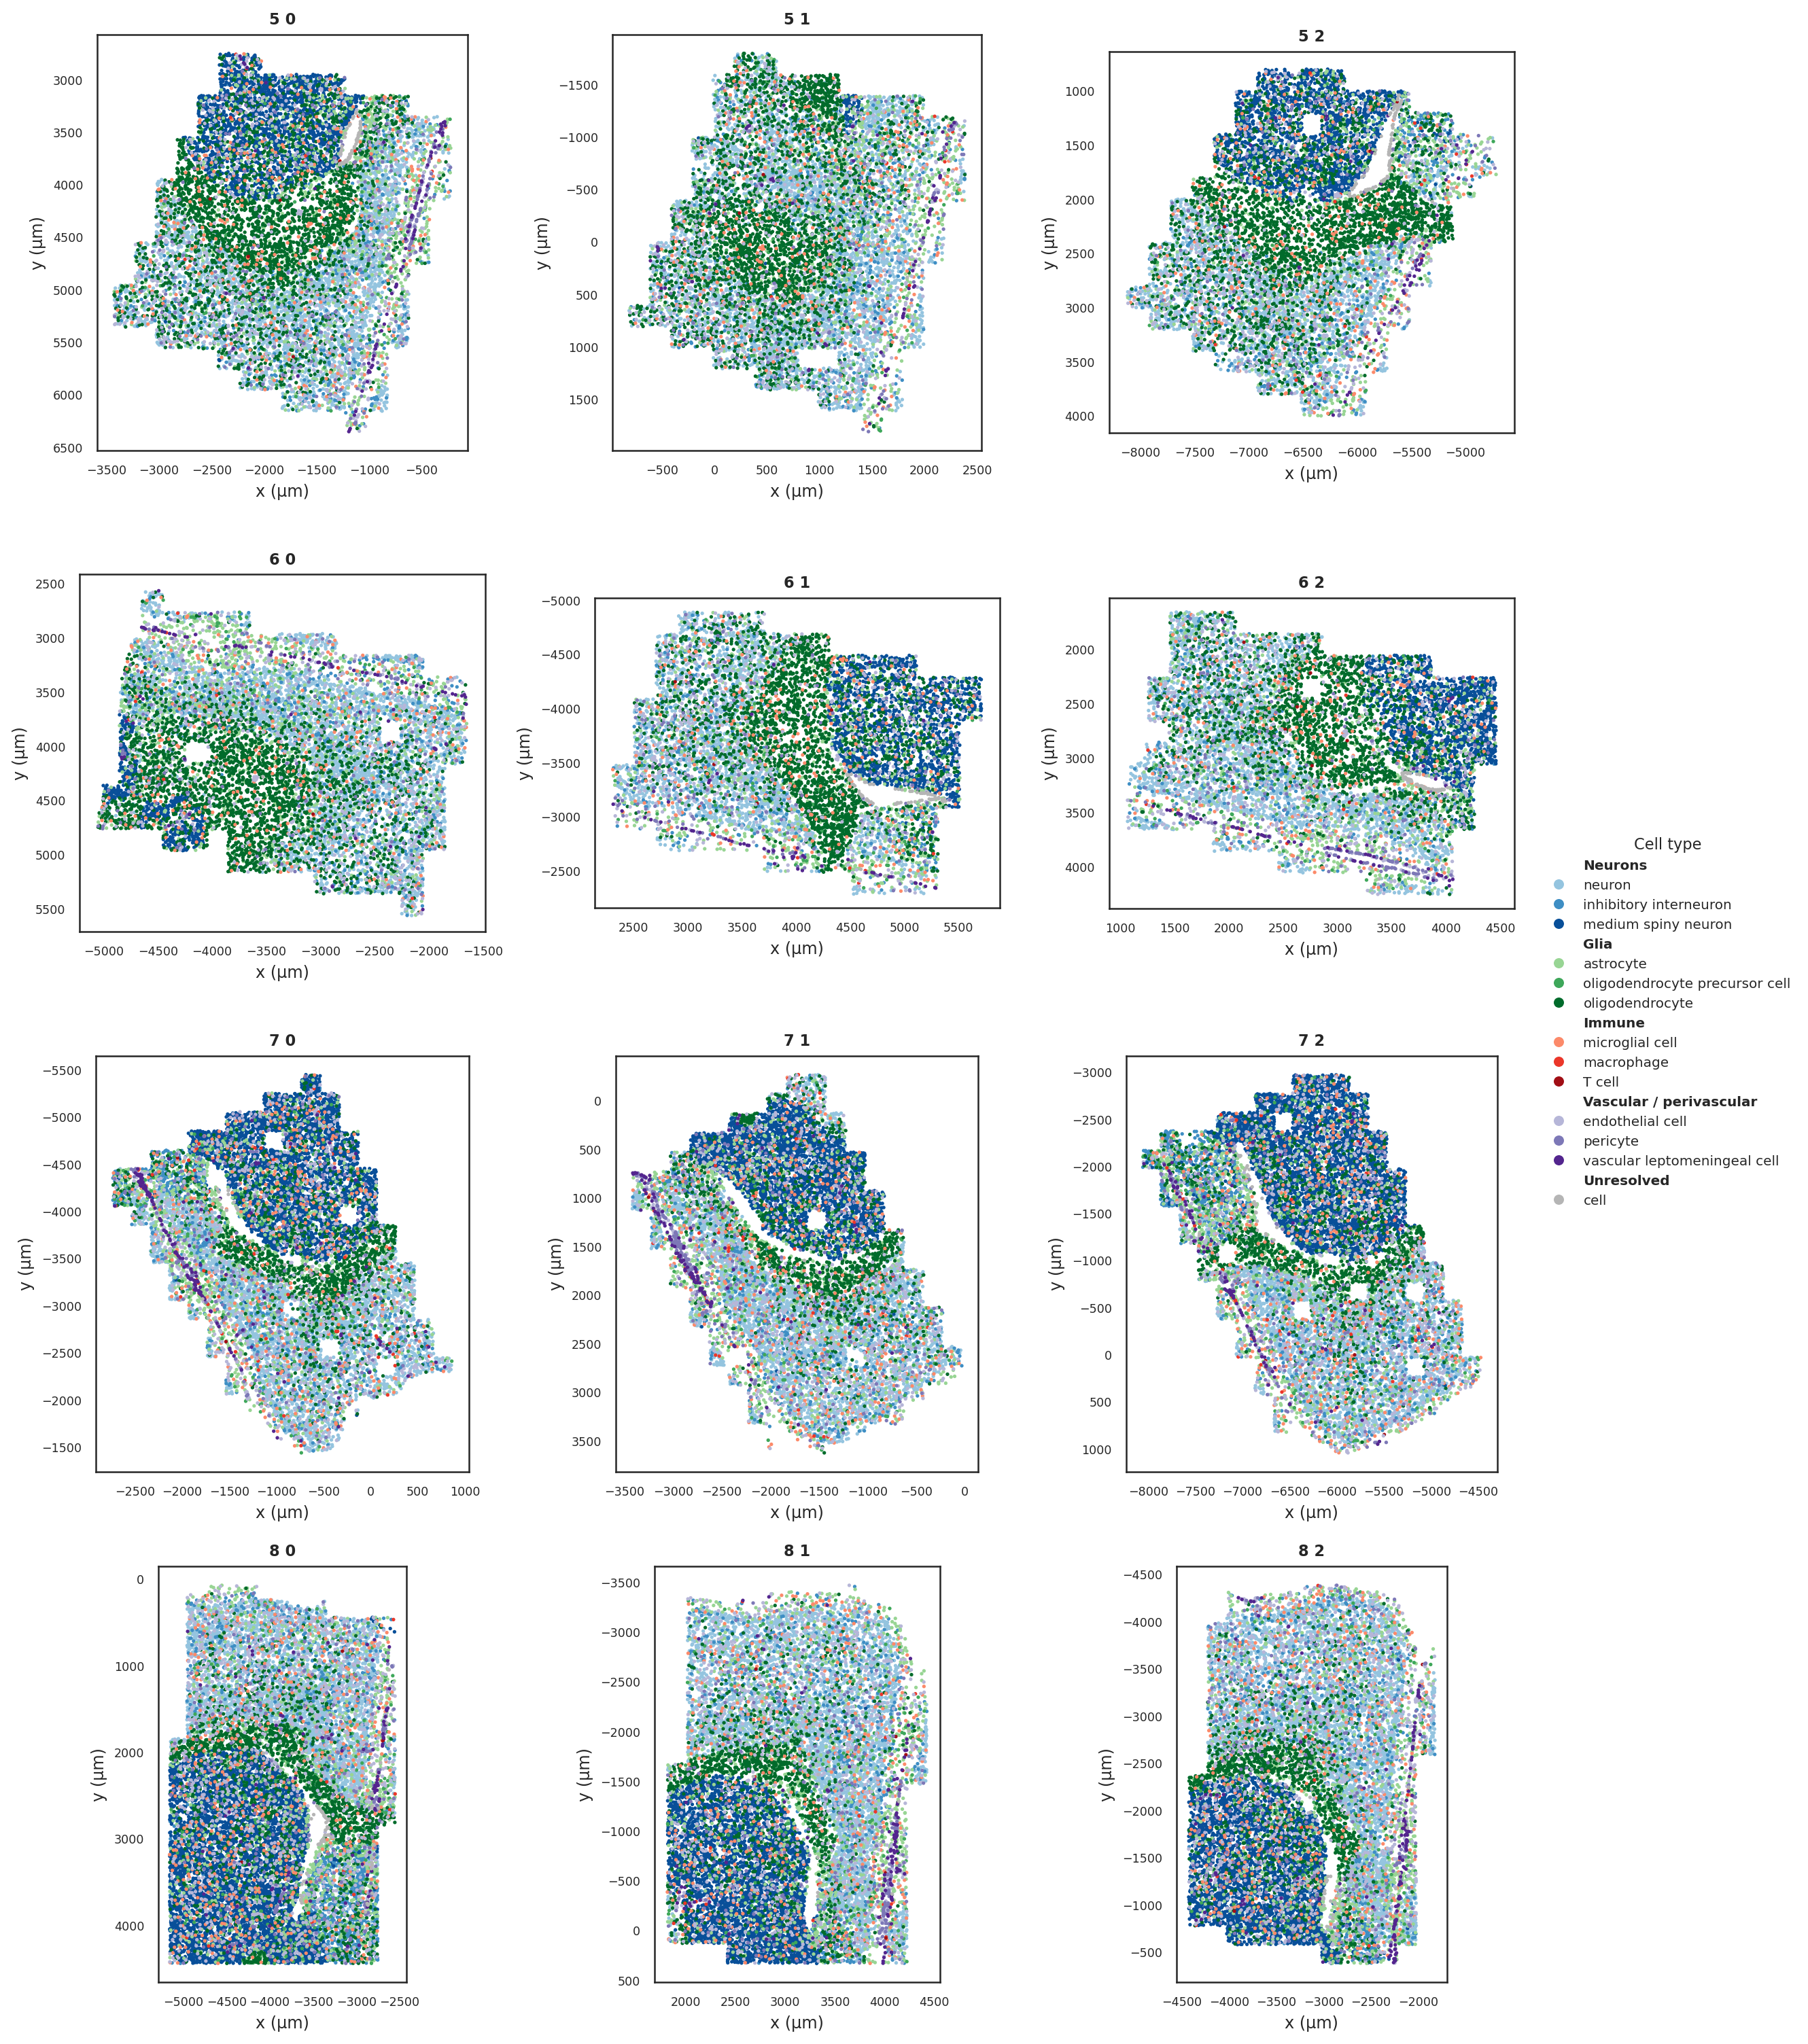

Saved figures and coverage: /home/jwinchel/Syndri/figures/outputs/slice_morphology/agingbrain_merfish_cell_types_6


In [15]:
n_rows = math.ceil(len(slices)/N_COLS)
fig, axes = plt.subplots(n_rows,N_COLS,figsize=(4.8*N_COLS,4.2*n_rows),
                         dpi=FIG_DPI,squeeze=False)
for ax,(sample,frame) in zip(axes.flat,slices):
    frame=frame.copy()
    frame['cell_type']=pd.Categorical(frame.cell_type,categories=cell_type_order,ordered=True)
    frame=frame.sort_values('cell_type')
    colors=[palette_dict[str(c)] for c in frame.cell_type]
    ax.scatter(frame.x,frame.y,c=colors,s=POINT_SIZE,linewidths=0,rasterized=True)
    ax.set_title(sample.replace('_',' '),fontsize=9,fontweight='bold')
    ax.set_xlabel(f'x ({COORDINATE_UNITS})');ax.set_ylabel(f'y ({COORDINATE_UNITS})')
    ax.set_aspect('equal',adjustable='box')
    if INVERT_Y_AXIS:ax.invert_yaxis()
    ax.tick_params(labelsize=7)
    if frame.empty:ax.text(.5,.5,'No valid annotated cells',transform=ax.transAxes,ha='center')
for ax in list(axes.flat)[len(slices):]:ax.set_visible(False)
handles=[]
family_header_indices=[]
for family,_,labels in family_groups:
    family_header_indices.append(len(handles))
    handles.append(Line2D([],[],linestyle='',label=family))
    handles.extend(Line2D([0],[0],marker='o',linestyle='',markerfacecolor=palette_dict[c],
                          markeredgecolor='none',markersize=6,label=c) for c in labels)
legend=fig.legend(handles=handles,title='Cell type',loc='center left',bbox_to_anchor=(.87,.5),
                  frameon=False,fontsize=8,title_fontsize=9)
for index in family_header_indices:legend.get_texts()[index].set_fontweight('bold')
fig.tight_layout(rect=(0,0,.87,1),h_pad=1.4,w_pad=1.2)
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
version=1
while any((OUTPUT_DIR/f'{OUTPUT_PREFIX}_{version}.{ext}').exists() for ext in ['png','pdf','csv']):
    version+=1
OUTPUT_STEM=OUTPUT_DIR/f'{OUTPUT_PREFIX}_{version}'
fig.savefig(OUTPUT_STEM.with_suffix('.png'),dpi=FIG_DPI,bbox_inches='tight')
fig.savefig(OUTPUT_STEM.with_suffix('.pdf'),bbox_inches='tight')
coverage.to_csv(OUTPUT_STEM.with_suffix('.csv'),index=False,mode='x')
family_color_table.to_csv(OUTPUT_STEM.parent/(OUTPUT_STEM.name+'_colors.csv'),index=False,mode='x')
plt.show()
print('Saved figures and coverage:',OUTPUT_STEM)
